# Notebook 4 - LLM Generation and System Evaluation

This notebook runs the **complete RAG evaluation pipeline**:

1. **Four-system ablation** on de-identified cases (S0–S3)
2. **100-question benchmark** built from KB topics and system use cases
3. **Retrieval metrics** — Precision@k / Recall@k vs gold chunks
4. **Full benchmark generation** — Ollama (default) + **GPT judge**

| System | Context |
|--------|---------|
| S0 baseline | dataset + prediction |
| S1 rag_xai | + local XAI + literature |
| S2 rag_agg_xai | + aggregated XAI + literature |
| S3 full | + local + aggregated XAI + literature |

**Env:** `XAI_LLM_BACKEND=ollama`, `XAI_JUDGE_BACKEND=openai`, `OPENAI_API_KEY`, `XAI_CASE_LIMIT`, `XAI_BENCHMARK_LIMIT` (default 100).  
Scripts: `python run_nb4.py`, `python run_rag_benchmark_full.py`.

In [16]:
# Optional: only if you want python-dotenv explicitly (llm_client loads .env without it)
%pip install python-dotenv

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup — Ollama (default) + GPT judge

| Role | Default backend | Override |
|------|-----------------|----------|
| Generation | **Ollama** (`llama3`, …) | `XAI_LLM_BACKEND=openai` |
| Judge | **GPT** | `XAI_JUDGE_BACKEND=ollama` |

Ollama preferred models: `llama3.1`, `llama3`, `gemma2`, `mistral`, `phi4`, `qwen2.5` (embedding models excluded).

In [17]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

import llm_client
import rag_benchmark_eval as rbe

OUTPUT_DIR = Path("outputs")
KB_DIR = OUTPUT_DIR / "kb"

LLM_OK = llm_client.is_available()
JUDGE_OK = llm_client.is_judge_available()
BENCHMARK_LIMIT = int(os.environ.get("XAI_BENCHMARK_LIMIT", "100"))

if LLM_OK:
    print(f"Ollama chat models: {llm_client.list_ollama_models()}")
    print(
        f"Generation ({llm_client.backend_name()}): {llm_client.model_name()} | "
        f"Judge ({llm_client.judge_backend_name()}): {llm_client.judge_model_name()}"
    )
else:
    print(
        "LLM unavailable. Start Ollama (`ollama serve`, `ollama pull llama3`) or set "
        "XAI_LLM_BACKEND=openai with OPENAI_API_KEY."
    )
print(f"Benchmark limit: {BENCHMARK_LIMIT} questions")

def generate(system, user, temperature=0.2):
    return llm_client.chat(system, user, temperature=temperature)


Ollama chat models: ['gemma2:latest', 'phi4:latest', 'mistral:latest', 'qwen2.5:1.5b', 'llama3:latest']
Generation (ollama): llama3:latest | Judge (openai): gpt-4o-mini
Benchmark limit: 100 questions


In [18]:
# generate() and judge() are provided by llm_client (see cell above)

## 2. Load knowledge base, retrieval, and artifacts

In [19]:
emb = np.load(KB_DIR / "embeddings.npy")
with open(KB_DIR / "documents.json", encoding="utf-8") as f:
    docs = json.load(f)
embedder = SentenceTransformer("all-MiniLM-L6-v2")


def retrieve(query, k=5):
    q = embedder.encode([query], normalize_embeddings=True).astype(np.float32)[0]
    sims = emb @ q
    return [docs[i] for i in np.argsort(sims)[::-1][:k]]


with open(OUTPUT_DIR / "local_explanations.json", encoding="utf-8") as f:
    local_cards = json.load(f)
with open(OUTPUT_DIR / "cards" / "aggregated_explanation.json", encoding="utf-8") as f:
    agg_card = json.load(f)
perf = pd.read_csv(OUTPUT_DIR / "model_performance.csv")
stab = pd.read_csv(OUTPUT_DIR / "stability_scores.csv")
faith = pd.read_csv(OUTPUT_DIR / "faithfulness.csv")
dataset_doc = next(d for d in docs if d["id"] == "dataset_overview")["text"]
CASE_LIMIT = int(os.environ.get("XAI_CASE_LIMIT", str(len(local_cards))))

c:\Users\test\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
c:\Users\test\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


## 3. Strict prompt and context builders

In [20]:
SYSTEM_PROMPT = (
    "You are a careful research assistant explaining a depression-risk SCREENING model. "
    "Use ONLY the provided context. Do NOT provide a clinical diagnosis. Explain the model "
    "prediction using the provided XAI evidence and retrieved student mental-health literature. "
    "Explicitly mention uncertainty and any model disagreement. End with a careful, supportive, "
    "non-clinical recommendation grounded in the literature when possible. "
    "Structure the answer with these sections: Prediction, Main contributing factors, "
    "Model agreement, Uncertainty, Interpretation, Recommendation.")


SYSTEMS = [
    ("baseline", "S0: Baseline RAG"),
    ("rag_xai", "S1: RAG + local XAI + literature"),
    ("rag_agg_xai", "S2: RAG + aggregated XAI + literature"),
    ("full", "S3: RAG + local + aggregated XAI + literature"),
]

BASELINE_PROMPT = (
    "You are a careful research assistant explaining a depression-risk SCREENING model. "
    "Use ONLY the provided context. Do NOT provide a clinical diagnosis. "
    "Explain the model prediction clearly. Mention uncertainty. "
    "End with a careful, supportive, non-clinical recommendation. "
    "Structure the answer with these sections: Prediction, Interpretation, Uncertainty, Recommendation."
)


def baseline_context(case):
    return (f"DATASET:\n{dataset_doc}\n\n"
            f"PREDICTION:\nPredicted class: {case['predicted_class']} "
            f"(probability {case['predicted_probability']}).")


def local_xai_block(case):
    factors = "\n".join(
        f"- {c['feature']} ({c['level']}): {c['direction']} (SHAP {c['shap_value']})"
        for c in case["top_contributing_factors"])
    return f"LOCAL XAI EVIDENCE (per-case top factors from CatBoost):\n{factors}"


def aggregated_xai_block():
    groups = "\n".join(
        f"- {g['group']}: importance {g['importance']}, agreement {g['agreement']}"
        for g in agg_card["top_feature_groups"][:5])
    return (f"AGGREGATED GLOBAL XAI EVIDENCE (feature groups across 9 models):\n{groups}\n\n"
            f"AGGREGATED INSIGHT:\n{agg_card['final_insight']}")


def literature_context(case, k=6):
    query = (
        f"college student depression anxiety {case['predicted_class']} "
        + " ".join(c["feature"] for c in case["top_contributing_factors"][:3])
    )
    hits = retrieve(query, k=k)
    blocks = []
    for d in hits:
        if d["type"] == "literature":
            blocks.append(f"[{d['title']}]\n{d['text'][:700]}")
    if not blocks:
        for d in hits:
            blocks.append(f"[{d['type']}] {d['title']}: {d['text'][:400]}")
    return "RETRIEVED LITERATURE (vector KB):\n" + "\n\n".join(blocks[:k])


def build_context(system_id, case):
    base = baseline_context(case)
    if system_id == "baseline":
        return base
    if system_id == "rag_xai":
        return f"{base}\n\n{local_xai_block(case)}\n\n{literature_context(case)}"
    if system_id == "rag_agg_xai":
        return f"{base}\n\n{aggregated_xai_block()}\n\n{literature_context(case)}"
    if system_id == "full":
        return (f"{base}\n\n{local_xai_block(case)}\n\n"
                f"{aggregated_xai_block()}\n\n{literature_context(case)}")
    raise ValueError(f"Unknown system: {system_id}")


def system_prompt(system_id):
    return BASELINE_PROMPT if system_id == "baseline" else SYSTEM_PROMPT

## 4. LLM-as-judge metrics (GPT default)

In [21]:
# GPT-as-judge metrics (via llm_client.judge -> XAI_OPENAI_JUDGE_MODEL)
from llm_client import judge

GROUNDED = "Rate how well the ANSWER is grounded in (entailed by) the CONTEXT (1=fully grounded, 0=hallucinated)."
RELEVANT = "Rate how relevant the ANSWER is to the QUESTION (1=fully relevant, 0=irrelevant)."
CTX_PREC = "Rate the fraction of the RETRIEVED context that is relevant to the QUESTION (1=all relevant)."
CTX_REC = "Rate the fraction of key facts in the ANSWER that are supported by the RETRIEVED context (1=all supported)."
HALLUC = "Rate the fraction of statements in the ANSWER that are NOT supported by the CONTEXT (1=all unsupported, 0=none)."


## 5. Generate and evaluate all four systems on de-identified cases

In [22]:
QUESTION = "Explain this student's depression-risk screening result and the main contributing factors."
rows = []
example_answers = {}

if LLM_OK:
    for case in local_cards[:CASE_LIMIT]:
        print(f"=== {case['case_id']} ===", flush=True)
        example_answers[case["case_id"]] = {}
        for system_id, label in SYSTEMS:
            print(f"  {label}...", flush=True)
            ctx = build_context(system_id, case)
            ans = generate(system_prompt(system_id), f"CONTEXT:\n{ctx}\n\nQUESTION: {QUESTION}")
            example_answers[case["case_id"]][system_id] = ans
            row = {
                "case": case["case_id"], "system": system_id,
                "llm_backend": llm_client.backend_name(),
                "llm_model": llm_client.model_name(),
                "judge_backend": llm_client.judge_backend_name(),
                "judge_model": llm_client.judge_model_name(),
                "faithfulness": judge(GROUNDED, f"CONTEXT:\n{ctx}\n\nANSWER:\n{ans}"),
                "answer_relevancy": judge(RELEVANT, f"QUESTION: {QUESTION}\n\nANSWER:\n{ans}"),
                "hallucination_rate": judge(HALLUC, f"CONTEXT:\n{ctx}\n\nANSWER:\n{ans}"),
            }
            if system_id == "baseline":
                row["context_precision"] = np.nan
                row["context_recall"] = np.nan
            else:
                retrieved = retrieve(QUESTION + " " + case["predicted_class"], k=8)
                ret_text = "\n".join(f"[{d['type']}] {d['title']}: {d['text'][:200]}" for d in retrieved)
                row["context_precision"] = judge(CTX_PREC, f"QUESTION: {QUESTION}\n\nRETRIEVED:\n{ret_text}")
                row["context_recall"] = judge(CTX_REC, f"ANSWER:\n{ans}\n\nRETRIEVED:\n{ret_text}")
            rows.append(row)
        print(f"  done {case['case_id']}", flush=True)
    evaldf = pd.DataFrame(rows)
    evaldf.to_csv(OUTPUT_DIR / "rag_evaluation.csv", index=False)
    evaldf.to_csv(OUTPUT_DIR / "rag_ablation_evaluation.csv", index=False)
else:
    evaldf = pd.DataFrame()
    print("Skipped live generation (LLM unavailable).")
evaldf

=== high_risk_case ===
  S0: Baseline RAG...
  S1: RAG + local XAI + literature...
  S2: RAG + aggregated XAI + literature...
  S3: RAG + local + aggregated XAI + literature...
  done high_risk_case
=== low_risk_case ===
  S0: Baseline RAG...
  S1: RAG + local XAI + literature...
  S2: RAG + aggregated XAI + literature...
  S3: RAG + local + aggregated XAI + literature...
  done low_risk_case
=== borderline_case ===
  S0: Baseline RAG...
  S1: RAG + local XAI + literature...
  S2: RAG + aggregated XAI + literature...
  S3: RAG + local + aggregated XAI + literature...
  done borderline_case


,case,system,llm_backend,llm_model,judge_backend,judge_model,faithfulness,answer_relevancy,hallucination_rate,context_precision,context_recall
0,high_risk_case,baseline,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,NaN,NaN
1,high_risk_case,rag_xai,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.1,0.5,0.9
2,high_risk_case,rag_agg_xai,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,0.5,0.5
3,high_risk_case,full,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,0.5,0.8
4,low_risk_case,baseline,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,NaN,NaN
5,low_risk_case,rag_xai,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,0.5,0.2
6,low_risk_case,rag_agg_xai,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,0.5,0.5
7,low_risk_case,full,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,0.5,0.4
8,borderline_case,baseline,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,NaN,NaN
9,borderline_case,rag_xai,ollama,llama3:latest,openai,gpt-4o-mini,1.0,1.0,0.2,0.5,0.8


## 6. Example final answer (full system)

In [23]:
if LLM_OK and example_answers:
    first = next(iter(example_answers))
    print(f"CASE: {first}\n")
    print(example_answers[first].get("full", ""))
else:
    print("No generated answers to display (LLM unavailable).")

CASE: high_risk_case

Prediction:
The model predicts that this student is at a high risk of experiencing elevated depression and/or anxiety, with a probability of 0.979.

Main Contributing Factors:
According to the local XAI evidence, the top features contributing to this prediction are:

* aca_impa (high): increases risk
* flourish (low): increases risk
* fincur (low): increases risk
* lonely (medium): increases risk
* food_worry (high): increases risk

These factors suggest that academic impact, financial stress, and social support may be playing a significant role in the student's depression-risk classification.

Model Agreement:
The aggregated global XAI evidence suggests that academic impact, social support and belonging, positive mental health, and financial stress are the strongest contributors to depression-risk classification. This agrees with the local XAI evidence highlighting the importance of academic impact and financial stress.

Uncertainty:
While the model is highly con

## 7. Four-system ablation comparison

,faithfulness,answer_relevancy,hallucination_rate,context_precision,context_recall
system,,,,,
baseline,1.0,1.0,0.200,NaN,NaN
rag_xai,1.0,1.0,0.167,0.5,0.633
rag_agg_xai,1.0,1.0,0.167,0.5,0.533
full,1.0,1.0,0.200,0.5,0.567


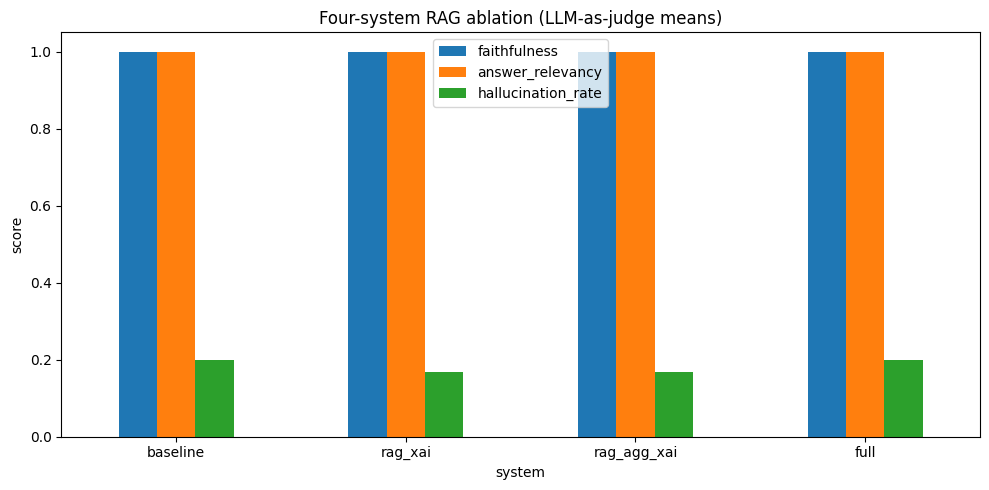

XAI-augmented systems — RAG retrieval quality (means):
             context_precision  context_recall
system                                        
full                       0.5           0.567
rag_agg_xai                0.5           0.533
rag_xai                    0.5           0.633


In [24]:
if not evaldf.empty:
    order = [s[0] for s in SYSTEMS]
    summary = (
        evaldf.groupby("system")[
            ["faithfulness", "answer_relevancy", "hallucination_rate", "context_precision", "context_recall"]
        ]
        .mean()
        .reindex(order)
    )
    display(summary.round(3))
    ax = summary[["faithfulness", "answer_relevancy", "hallucination_rate"]].plot.bar(figsize=(10, 5), rot=0)
    ax.set_title("Four-system RAG ablation (LLM-as-judge means)")
    ax.set_ylabel("score")
    plt.tight_layout(); plt.show()
    xai = evaldf[evaldf.system != "baseline"]
    print("XAI-augmented systems — RAG retrieval quality (means):")
    print(xai.groupby("system")[["context_precision", "context_recall"]].mean().round(3).to_string())

## 8. Full-system evaluation summary

In [25]:
print("=== Model performance (test set) ===")
print(perf[["model", "family", "auc", "macro_f1", "recall", "pr_auc", "brier"]].round(4).to_string(index=False))
print("\n=== Explanation faithfulness (deletion test, AUC drop) ===")
print(faith.round(4).to_string(index=False))
print("\n=== Explanation stability and model weights ===")
print(stab[["model", "stability_score", "calibration_score", "model_weight"]].round(4).to_string(index=False))

=== Model performance (test set) ===
              model family    auc  macro_f1  recall  pr_auc  brier
            XGBoost     ML 0.8532    0.7715  0.7690  0.8231 0.1561
           LightGBM     ML 0.8525    0.7688  0.7690  0.8235 0.1568
           CatBoost     ML 0.8520    0.7704  0.7718  0.8248 0.1569
     FT-Transformer     DL 0.8518    0.7668  0.7889  0.8239 0.1580
     TabTransformer     DL 0.8512    0.7632  0.6776  0.8238 0.1574
              DCNv2     DL 0.8499    0.7687  0.7452  0.8228 0.1570
      Random Forest     ML 0.8486    0.7669  0.7592  0.8197 0.1577
        Extra Trees     ML 0.8482    0.7664  0.7644  0.8188 0.1583
Logistic Regression     ML 0.8469    0.7645  0.7588  0.8175 0.1596

=== Explanation faithfulness (deletion test, AUC drop) ===
              model  base_auc  masked_top5_auc  auc_drop
              DCNv2    0.8499           0.6443    0.2056
      Random Forest    0.8486           0.6523    0.1963
        Extra Trees    0.8482           0.6602    0.1880
     

## 9. Ethical limitations

- This system is **not a diagnostic tool** and must not replace mental-health professionals.
- Predictions are **screening signals** and may contain **bias**, especially for sensitive features
  (gender, race, sexual-orientation discrimination).
- **Sensitive features must be handled carefully**, reported at group level, and never used for
  individual screening without clinical validation.
- The system must **preserve privacy and de-identification** (local explanations are bucketed and
  carry no identifiers).
- **LLM answers must be grounded** only in retrieved evidence and must state uncertainty and model
  disagreement.

**Expected result:** the XAI-augmented RAG system produces more transparent, evidence-based, and
trustworthy explanations than a classical RAG system that sees only the dataset and the prediction.

## 10. Paper-aligned RAGAS evaluation (100-question benchmark)

The **100-question labeled benchmark** and **RAGAS evaluation** (six metrics from Batal et al., 2026) live in a dedicated citable notebook:

**[07_ragas_benchmark_evaluation.ipynb](07_ragas_benchmark_evaluation.ipynb)**

Run: `python run_nb7.py` or open notebook 07.


In [33]:
print("Notebook 4 complete.")

Notebook 4 complete.
